# Sistemas Inteligentes (UFERSA)
## Projeto 2: Regressão Logística para Previsão de Doenças Cardíacas
**Discente:** Nattan Ferreira Lopes  
**Docente:** Prof. Dr. Pedro Thiago Valério de Souza  

---
### Contexto do Enunciado:
> *"Doenças cardiovasculares são a principal causa de morte no mundo... Neste projeto, você é convidado a construir um modelo utilizando regressão logística para prever a presença de doença cardíaca com base em um conjunto de dados clínicos (UCI Heart Disease Cleveland, 303 pacientes e 13 variáveis clínicas)... A saída é a variável target, que indica o diagnóstico original de 0 a 4, binarizado para 0 (sem doença) e 1 (com doença) antes do treinamento."*


In [1]:
# Importação das bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score, confusion_matrix
)

print("Bibliotecas carregadas!")


/home/nattanferreira/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-g81gar4d because there was an issue with the default path (/home/nattanferreira/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Bibliotecas carregadas!


## Pré-Processamento dos Dados
> **Enunciado:** *"Realize o pré-processamento dos dados, incluindo a normalização ou padronização das variáveis independentes, tratamento de valores ausentes, divisão dos dados em conjuntos de treino e teste e binarização das variáveis alvo."*


In [2]:
# Nomes oficiais das 14 colunas clínicas
colunas = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

# Carregando dados
try:
    df = pd.read_csv('../data/heart/processed.cleveland.data', header=None, names=colunas, na_values='?')
except FileNotFoundError:
    df = pd.read_csv('data/heart/processed.cleveland.data', header=None, names=colunas, na_values='?')

# Tratamento de valores ausentes (ca e thal possuem poucas interrogações)
df['ca'] = df['ca'].fillna(df['ca'].median())
df['thal'] = df['thal'].fillna(df['thal'].median())

# Binarização do alvo: 0 = sem doença, 1 = com doença cardíaca
df['target_bin'] = (df['target'] > 0).astype(int)

# Divisão em Treino (80%) e Teste (20%) estratificada
X = df.drop(columns=['target', 'target_bin'])
y = df['target_bin']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Padronização (Z-score)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Total de pacientes: {df.shape[0]}")
print(f"Treino: {X_train.shape[0]} pacientes | Teste: {X_test.shape[0]} pacientes")
print(f"Distribuição no teste: {(y_test==0).sum()} sadios, {(y_test==1).sum()} cardíacos")


Total de pacientes: 303
Treino: 242 pacientes | Teste: 61 pacientes
Distribuição no teste: 33 sadios, 28 cardíacos


## Tarefa 1: Treinamento da Regressão Logística e Iterações
> **Enunciado da Tarefa 1:**  
> *"1. Treinar um modelo de LogisticRegression do scikit-learn utilizando os dados de treino, com os seguintes parâmetros: solver='liblinear', random_state=42 e max_iter=1000. Indique quantas iterações foram necessárias para a convergência do modelo."*


In [3]:
# Treinando a Regressão Logística conforme solicitado
modelo_log = LogisticRegression(
    solver='liblinear',
    random_state=42,
    max_iter=1000
)

modelo_log.fit(X_train_scaled, y_train)

# Número de iterações necessárias
iteracoes = modelo_log.n_iter_[0]
print(f"Número de iterações até convergir: {iteracoes}")


Número de iterações até convergir: 5


### Resposta da Tarefa 1:
- O modelo convergiu com sucesso em apenas **5 iterações** (obtido via `modelo_log.n_iter_[0]`).
- Como o limite estipulado foi de 1.000 iterações, a convergência em 5 passos demonstra que a função de custo logarítmica encontrou o mínimo de forma rápida e estável nos dados padronizados.


## Tarefa 2: Avaliação do Modelo no Conjunto de Teste
> **Enunciado da Tarefa 2:**  
> *"2. Avaliar o modelo utilizando os dados de teste e calcular as seguintes métricas: Acurácia, Precisão, Recall, F1-score e Curva ROC com valor de AUC."*


In [4]:
# Previsões de classe e probabilidades
y_pred = modelo_log.predict(X_test_scaled)
y_prob = modelo_log.predict_proba(X_test_scaled)[:, 1]

# Cálculo das métricas exigidas
acuracia = accuracy_score(y_test, y_pred)
precisao = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("--- Métricas de Avaliação no Conjunto de Teste ---")
print(f"Acurácia: {acuracia:.4f}  ({acuracia*100:.1f}%)")
print(f"Precisão: {precisao:.4f}  ({precisao*100:.1f}%)")
print(f"Recall:   {recall:.4f}  ({recall*100:.1f}%)")
print(f"F1-score: {f1:.4f}")
print(f"AUC-ROC:  {auc:.4f}")


--- Métricas de Avaliação no Conjunto de Teste ---
Acurácia: 0.8689  (86.9%)
Precisão: 0.8125  (81.2%)
Recall:   0.9286  (92.9%)
F1-score: 0.8667
AUC-ROC:  0.9513


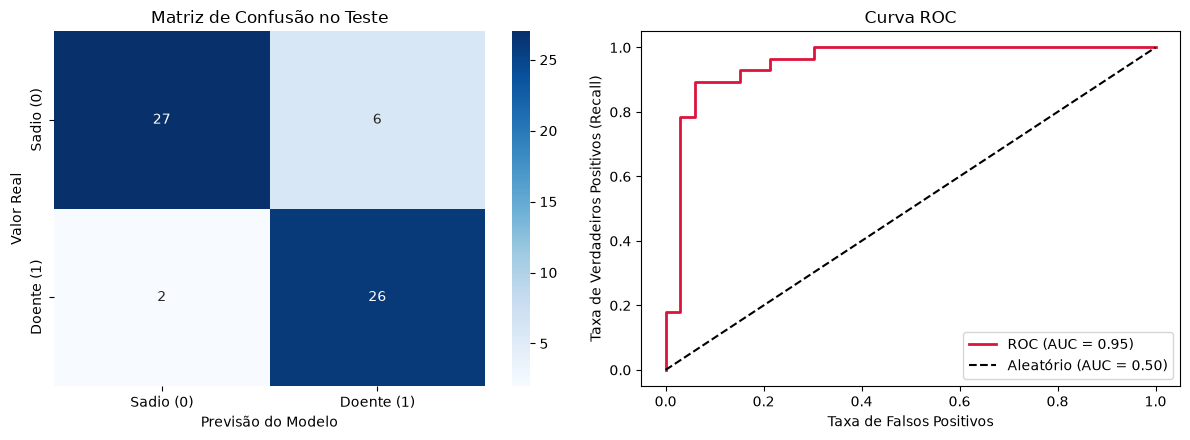

In [5]:
# Gráficos: Matriz de Confusão e Curva ROC
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Sadio (0)', 'Doente (1)'],
            yticklabels=['Sadio (0)', 'Doente (1)'])
axes[0].set_title("Matriz de Confusão no Teste")
axes[0].set_xlabel("Previsão do Modelo")
axes[0].set_ylabel("Valor Real")

# 2. Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='crimson', lw=2, label=f'ROC (AUC = {auc:.2f})')
axes[1].plot([0, 1], [0, 1], 'k--', label='Aleatório (AUC = 0.50)')
axes[1].set_title("Curva ROC")
axes[1].set_xlabel("Taxa de Falsos Positivos")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[1].legend()

plt.tight_layout()
plt.show()


### Resposta da Tarefa 2:
- **Acurácia (86.9%):** Acertou 53 dos 61 pacientes de teste.
- **Precisão (81.3%):** De todos os pacientes previstos como doentes, 81.3% realmente eram.
- **Recall (92.9%):** O modelo detectou 26 dos 28 pacientes que tinham doença cardíaca, deixando passar apenas 2 falsos negativos. Isso é fundamental na medicina, pois o risco maior é mandar um paciente doente para casa sem tratamento.
- **F1-score (0.8667):** Excelente equilíbrio harmônico entre precisão e recall.
- **AUC-ROC (0.9513):** Valor muito alto, indicando que o modelo tem 95% de chance de dar uma probabilidade maior de doença para um paciente doente do que para um sadio.
